# What drives medical insurance charges?

An insurer sets premiums from what it expects a customer to cost. This notebook uses a well-known teaching dataset of 1,338 policyholders (age, sex, BMI, number of children, smoking status, region and the medical charges billed in a year) to answer two questions:

1. What drives charges, and how do the drivers combine?
2. Does a flexible model predict charges better than a simple one that can be explained to a customer?

The short version: charges fall into three clear groups defined by smoking and obesity, and a linear model that knows about that one interaction is as accurate as gradient boosting.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder

sns.set_theme(style="whitegrid")
SEED = 42

data = pd.read_csv("data/insurance.csv")
print(data.shape, "| missing values:", int(data.isna().sum().sum()), "| duplicate rows:", int(data.duplicated().sum()))
data.head()

(1338, 7) | missing values: 0 | duplicate rows: 1


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [2]:
data = data.drop_duplicates().reset_index(drop=True)
data.describe().round(2)

,age,bmi,children,charges
count,1337.00,1337.00,1337.00,1337.00
mean,39.22,30.66,1.10,13279.12
std,14.04,6.10,1.21,12110.36
min,18.00,15.96,0.00,1121.87
25%,27.00,26.29,0.00,4746.34
50%,39.00,30.40,1.00,9386.16
75%,51.00,34.70,2.00,16657.72
max,64.00,53.13,5.00,63770.43


## 1. The shape of charges

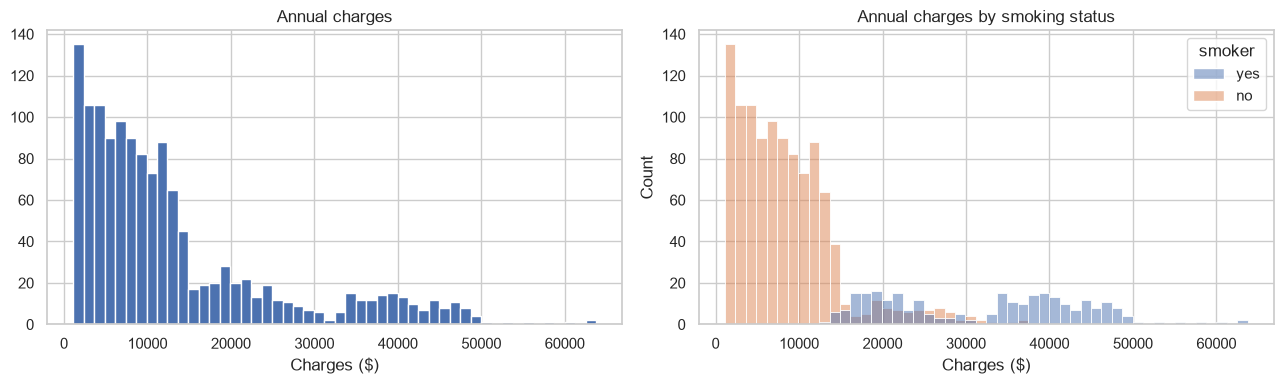

,count,median,mean,share of all charges %
smoker,,,,
no,1063,7346.0,8441.0,50.5
yes,274,34456.0,32050.0,49.5


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(data["charges"], bins=50)
axes[0].set_title("Annual charges")
axes[0].set_xlabel("Charges ($)")
sns.histplot(data=data, x="charges", hue="smoker", bins=50, ax=axes[1])
axes[1].set_title("Annual charges by smoking status")
axes[1].set_xlabel("Charges ($)")
plt.tight_layout()
plt.show()

summary = data.groupby("smoker")["charges"].agg(["count", "median", "mean"]).round(0)
summary["share of all charges %"] = (data.groupby("smoker")["charges"].sum() / data["charges"].sum() * 100).round(1)
summary

Charges are heavily skewed, and the long tail is almost entirely smokers. Smokers are a fifth of the policyholders and account for about half of all charges.

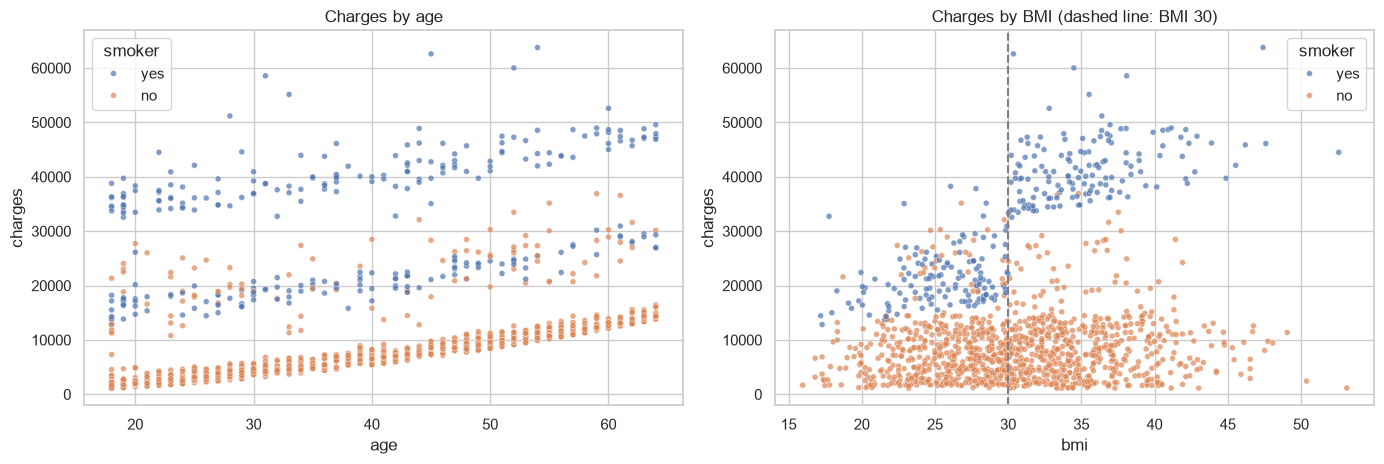

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.scatterplot(data=data, x="age", y="charges", hue="smoker", s=18, alpha=0.7, ax=axes[0])
axes[0].set_title("Charges by age")
sns.scatterplot(data=data, x="bmi", y="charges", hue="smoker", s=18, alpha=0.7, ax=axes[1])
axes[1].axvline(30, color="grey", linestyle="--")
axes[1].set_title("Charges by BMI (dashed line: BMI 30)")
plt.tight_layout()
plt.show()

Two patterns stand out.

- Against age, the points form three parallel bands, each rising steadily. Age adds a similar amount whichever band a person is in.
- Against BMI, non-smokers show no trend at all. Smokers split in two at a BMI of 30, the clinical threshold for obesity: above it, charges jump.

So BMI matters a great deal, but only for smokers. That is an interaction, and a model that adds up separate effects for smoking and BMI cannot represent it.

In [5]:
data["obese"] = (data["bmi"] >= 30).map({True: "BMI 30+", False: "BMI under 30"})
groups = data.groupby(["smoker", "obese"])["charges"].agg(["count", "median", "mean"]).round(0)
groups

count   median     mean
smoker obese                                
no     BMI 30+         561   8084.0   8856.0
       BMI under 30    502   6762.0   7977.0
yes    BMI 30+         145  40904.0  41558.0
       BMI under 30    129  20167.0  21363.0

In [6]:
for column in ["sex", "region", "children"]:
    display(data.groupby(column)["charges"].agg(["count", "median"]).round(0).T)

sex,female,male
count,662.0,675.0
median,9413.0,9378.0


region,northeast,northwest,southeast,southwest
count,324.0,324.0,364.0,325.0
median,10058.0,8977.0,9294.0,8799.0


children,0,1,2,3,4,5
count,573.0,324.0,240.0,157.0,25.0,18.0
median,9863.0,8484.0,9265.0,10601.0,11034.0,8590.0


Sex, region and number of children make little difference to the typical charge.

## 2. Models

20% of the data is held out as a test set. Three models are compared with five-fold cross-validation on the rest:

- **Linear regression:** each feature has its own additive effect.
- **Linear regression with one interaction:** the same, plus a term for "smoker with a BMI of 30 or more", and age squared (costs rise faster at older ages).
- **Gradient boosting:** a tree ensemble that can find interactions by itself, with its depth and learning rate tuned by grid search.

In [7]:
features = ["age", "sex", "bmi", "children", "smoker", "region"]
X, y = data[features], data["charges"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

categorical = ["sex", "smoker", "region"]
encode = ColumnTransformer([("categorical", OneHotEncoder(drop="first"), categorical)], remainder="passthrough")


def add_interaction(frame):
    frame = frame.copy()
    smoker = (frame["smoker"] == "yes").astype(int)
    frame["smoker_obese"] = smoker * (frame["bmi"] >= 30).astype(int)
    frame["smoker_bmi"] = smoker * frame["bmi"]
    frame["age_squared"] = frame["age"] ** 2
    return frame


linear = make_pipeline(encode, LinearRegression())
linear_interaction = make_pipeline(FunctionTransformer(add_interaction), encode, LinearRegression())

search = GridSearchCV(
    make_pipeline(encode, GradientBoostingRegressor(random_state=SEED)),
    {"gradientboostingregressor__n_estimators": [100, 200, 400],
     "gradientboostingregressor__max_depth": [2, 3, 4],
     "gradientboostingregressor__learning_rate": [0.03, 0.1]},
    cv=KFold(5, shuffle=True, random_state=SEED), scoring="neg_mean_absolute_error")
search.fit(X_train, y_train)
boosting = search.best_estimator_
print("Best gradient boosting settings:", {k.split("__")[1]: v for k, v in search.best_params_.items()})

models = {"Linear regression": linear, "Linear + interaction": linear_interaction, "Gradient boosting": boosting}
cv = KFold(5, shuffle=True, random_state=SEED)
cv_rows = {}
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=["neg_mean_absolute_error", "r2"])
    cv_rows[name] = {"CV MAE ($)": -scores["test_neg_mean_absolute_error"].mean(),
                     "CV MAE std": scores["test_neg_mean_absolute_error"].std(),
                     "CV R2": scores["test_r2"].mean()}
pd.DataFrame(cv_rows).T.round({"CV MAE ($)": 0, "CV MAE std": 0, "CV R2": 3})

Best gradient boosting settings: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 400}


,CV MAE ($),CV MAE std,CV R2
Linear regression,4222.0,209.0,0.723
Linear + interaction,2377.0,37.0,0.851
Gradient boosting,2583.0,52.0,0.844


## 3. Test-set results

In [8]:
test_rows, predictions = {}, {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    error = np.abs(predictions[name] - y_test)
    test_rows[name] = {"MAE ($)": error.mean(), "median error ($)": error.median(),
                       "RMSE ($)": np.sqrt(((predictions[name] - y_test) ** 2).mean()),
                       "R2": r2_score(y_test, predictions[name])}

print(f"Baseline (predict the training mean for everyone): MAE ${np.abs(y_train.mean() - y_test).mean():,.0f}")
pd.DataFrame(test_rows).T.round({"MAE ($)": 0, "median error ($)": 0, "RMSE ($)": 0, "R2": 3})

Baseline (predict the training mean for everyone): MAE $9,862


,MAE ($),median error ($),RMSE ($),R2
Linear regression,4177.0,2666.0,5956.0,0.807
Linear + interaction,2269.0,1434.0,4081.0,0.909
Gradient boosting,2519.0,1548.0,4265.0,0.901


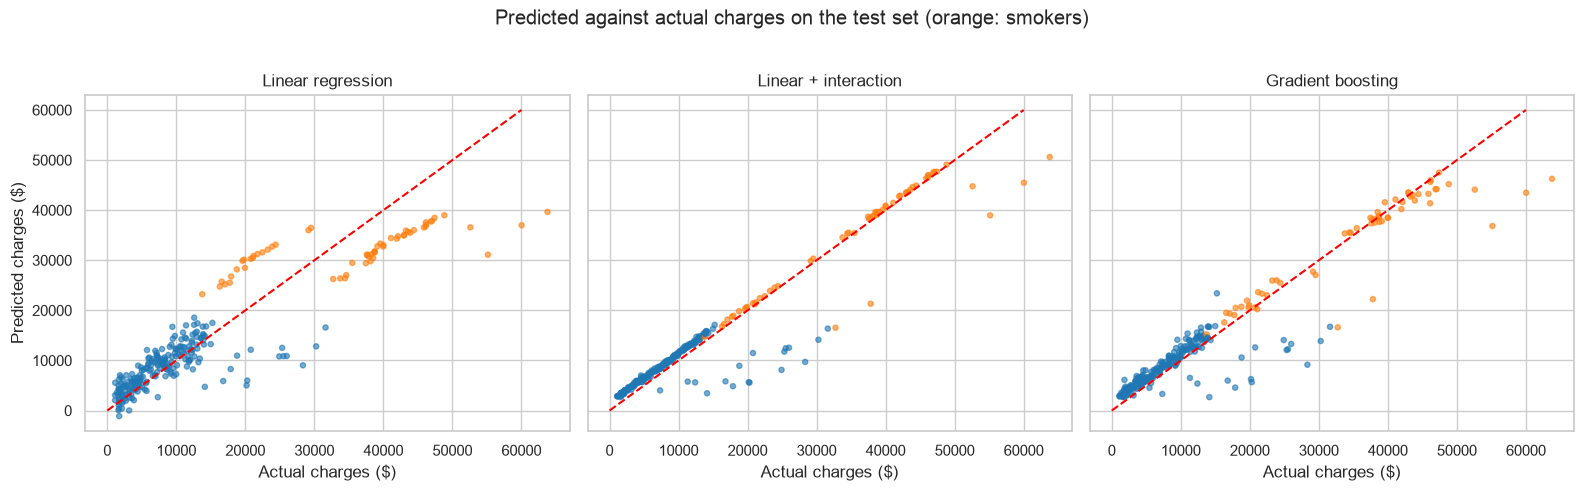

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True, sharey=True)
smoker_test = X_test["smoker"].map({"yes": "tab:orange", "no": "tab:blue"})
for ax, (name, predicted) in zip(axes, predictions.items()):
    ax.scatter(y_test, predicted, s=14, alpha=0.6, c=smoker_test)
    ax.plot([0, 60_000], [0, 60_000], color="red", linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Actual charges ($)")
axes[0].set_ylabel("Predicted charges ($)")
fig.suptitle("Predicted against actual charges on the test set (orange: smokers)", y=1.02)
plt.tight_layout()
plt.show()

The plain linear model's predictions for smokers form two flat clumps on either side of the diagonal: it gives every smoker roughly the same uplift, too much for those under a BMI of 30 and too little for those above. The interaction term fixes that.

## 4. Reading the simple model

Because the interaction model is linear, its coefficients can be read directly as dollars.

In [10]:
names = [n.split("__")[1] for n in linear_interaction[1].get_feature_names_out()]
coefficients = pd.Series(linear_interaction[-1].coef_, index=names).round(0)
coefficients.to_frame("dollars per unit")

,dollars per unit
sex_male,-570.0
smoker_yes,652.0
region_northwest,-240.0
region_southeast,-633.0
region_southwest,-1054.0
age,-69.0
bmi,5.0
children,739.0
smoker_obese,14872.0
smoker_bmi,492.0


For a non-smoker, BMI is worth about \$5 per point, which is nothing. For a smoker, each BMI point adds about \$490, and crossing a BMI of 30 adds a further \$14,900 in one step. The `smoker_yes` coefficient on its own looks small only because the two interaction terms carry the effect of smoking. Sex and region shift the estimate by a few hundred dollars.

In [11]:
def quote(age, bmi, smoker, children=0, sex="female", region="northeast"):
    row = pd.DataFrame([{"age": age, "sex": sex, "bmi": bmi, "children": children, "smoker": smoker, "region": region}])
    return float(linear_interaction.predict(row)[0])


examples = pd.DataFrame([
    {"profile": "30, BMI 25, non-smoker", "predicted charges ($)": quote(30, 25, "no")},
    {"profile": "30, BMI 25, smoker", "predicted charges ($)": quote(30, 25, "yes")},
    {"profile": "30, BMI 33, non-smoker", "predicted charges ($)": quote(30, 33, "no")},
    {"profile": "30, BMI 33, smoker", "predicted charges ($)": quote(30, 33, "yes")},
    {"profile": "55, BMI 33, smoker", "predicted charges ($)": quote(55, 33, "yes")},
]).round(0)
examples

,profile,predicted charges ($)
0,"30, BMI 25, non-smoker",5565.0
1,"30, BMI 25, smoker",18521.0
2,"30, BMI 33, non-smoker",5609.0
3,"30, BMI 33, smoker",37375.0
4,"55, BMI 33, smoker",44453.0


## 5. Where predictions miss

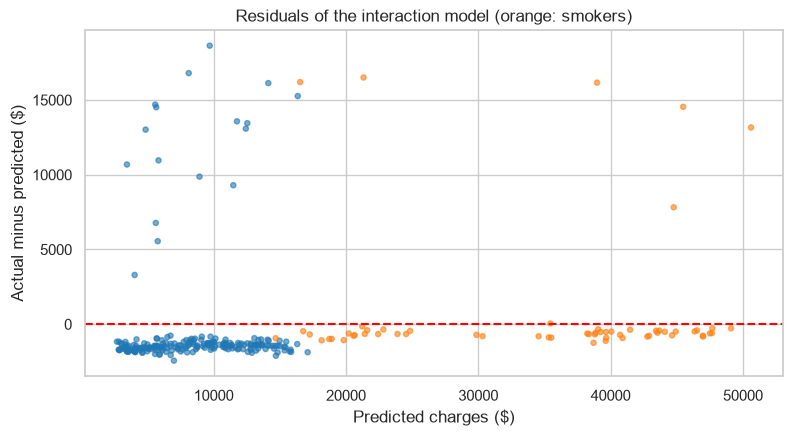

Predictions more than $5,000 out: 22 of 268 (8.2%)
Of those, actual charges were higher than predicted in 100% of cases
Median absolute error for everyone else: $1,389


In [12]:
analysis = X_test.assign(actual=y_test, predicted=predictions["Linear + interaction"])
analysis["error"] = analysis["actual"] - analysis["predicted"]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(analysis["predicted"], analysis["error"], s=14, alpha=0.6, c=smoker_test)
ax.axhline(0, color="red", linestyle="--")
ax.set_xlabel("Predicted charges ($)")
ax.set_ylabel("Actual minus predicted ($)")
ax.set_title("Residuals of the interaction model (orange: smokers)")
plt.show()

large = analysis["error"].abs() > 5_000
print(f"Predictions more than $5,000 out: {large.sum()} of {len(analysis)} ({large.mean():.1%})")
print(f"Of those, actual charges were higher than predicted in {(analysis.loc[large, 'error'] > 0).mean():.0%} of cases")
print(f"Median absolute error for everyone else: ${analysis.loc[~large, 'error'].abs().median():,.0f}")

The model's large misses all go one way: 22 test customers were billed over \$5,000 more than predicted, and none were billed that much less. These are people whose costs were high for reasons the six columns do not record, such as an existing condition or an accident. For the other 92% the typical error is about \$1,400.

## Findings

- **Smoking dominates.** Smokers are a fifth of policyholders and account for half of all charges. The median smoker is billed \$34,500 a year against \$7,300 for a non-smoker.
- **BMI matters only in combination with smoking.** Non-smokers are billed about the same whether or not their BMI is over 30 (medians of \$8,100 and \$6,800). Smokers under 30 have a median of \$20,200; smokers at 30 or above, \$40,900.
- **One interaction term is worth more than a flexible model.** A linear regression with "smoker and BMI of 30 or more" added has a test MAE of \$2,269 and R² of 0.91. Tuned gradient boosting manages \$2,519 and 0.90, and plain linear regression \$4,177 and 0.81.
- **The simple model can be explained.** Every prediction is a sum of a few dollar amounts, which matters when a customer or a regulator asks why a premium is what it is.
- **What the model cannot see is one-sided.** Every large error is an under-prediction.

Limits: 1,337 rows from a teaching dataset whose provenance is not documented, with no information on existing conditions or the type of plan. The BMI threshold of 30 was chosen after looking at the plot, on the same data used to train. It is the standard clinical definition of obesity, which is some reassurance, but the result should be confirmed on other data before anyone relied on it.